# Verra 專案 Proponents 所屬國家分析

資料來源:`Verra_active_project.xlsx` 的 `Proponents` 欄。目標是把每家公司歸到「所屬國家」,最後畫成世界地圖。

**分類規則**
1. `Multiple Project Proponents` 跳過(另外 `Credits transferred...`、`Converted...` 不是公司名稱,也跳過)
2. 公司有多國持股 → 看持股最多的國家;對半的話兩國都算
3. 公司只有一個國家持有 → 直接算那個國家

**執行環境**:conda 環境 `Geography`。下面所有檔案都放在這個 notebook 同一個資料夾。

**步驟**
- Step 1 載入套件與設定
- Step 2 讀取 Excel、套用跳過規則
- Step 3 每家公司彙總(專案數、專案所在國)
- Step 4 分類函式(查證結果 → 手動指定 → 專案所在國推斷)
- Step 5 執行分類並輸出 CSV
- Step 6 逐國展開(持股對半的兩國都算)與統計
- Step 7 畫世界地圖(最後一格,可自行修改)

## Step 1. 載入套件與設定

In [1]:
import re
import sys
from pathlib import Path

import pandas as pd

# notebook 所在資料夾;輸出的 CSV / 圖片都存在這裡
HERE = Path.cwd()
# 資料夾結構:code/(程式) data/(csv) Photo/(圖);不管從 code 或上層資料夾開 notebook 都會找到正確位置
ROOT = HERE.parent if HERE.name == "code" else HERE
CODE, DATA, PHOTO = ROOT / "code", ROOT / "data", ROOT / "Photo"
DATA.mkdir(exist_ok=True); PHOTO.mkdir(exist_ok=True)
sys.path.insert(0, str(CODE))

# 兩份「人工整理」的對照表(同一資料夾的 .py 檔):
#   researched_ownership.py = 上網查證持股的結果(含依據 note)
#   country_overrides.py    = 手動指定的國別
#   location_checks.py      = 用 "<公司名> company location" 逐家搜尋所在地的結果
from country_overrides import OVERRIDES
from researched_ownership import RESEARCHED
from location_checks import LOCATIONS   # 中國/土耳其推斷公司的「公司所在地」網路搜尋結果

# Excel 路徑,換電腦或搬檔案時改這裡
SRC = Path("/Users/peterchang/Downloads/Verra_active_project.xlsx")

# 這幾種開頭的 Proponents 不是單一公司,直接跳過
SKIP_PREFIXES = ("Multiple Project Proponents", "Credits transferred", "Converted")

# 國名統一(Excel 內的寫法 → 地圖用的寫法)
COUNTRY_RENAME = {
    "United States of America": "United States",
    "Korea (Republic of)": "South Korea",
    "Tanzania, United Republic of": "Tanzania",
    "Lao People's Democratic Republic": "Laos",
}

# 推斷用:專案所在國 → 該國常見的公司名稱格式(正規表示式)
# 例如專案在中國,名字含 "Co., Ltd" 就推斷是中國公司
LOCAL_FORMS = {
    "Mainland China": r"Co\.?,? ?Ltd|Co\.,|Company Limited|Group|Station|Workstation|Forestry|Center|Corporation",
    "India": r"Pvt|Private Limited|Limited|Ltd|LLP|M/s|Foundation|Department",
    "Turkey": r"A\.?\s?[SŞ]\.?|ANON[İI]M|Şti|Sti\b|Elektrik|Enerji|Ltd\. ?Şirketi|LİMİTED",
    "Brazil": r"ltda|S/A|S\.A\.|\bSA\b|Participa",
    "Colombia": r"S\.A\.S|E\.S\.P|S\.A\.|SAS\b|Consejo|Fundaci",
    "Mexico": r"S\.A\.|S\. de R\.L|C\.V\.",
    "Uruguay": r"S\.A\.|\bSA\b|S\.R\.L|SRL|SAS|S\.A\.C",
    "Paraguay": r"S\.A\.|\bSA\b|SRL|S\.R\.L|SAS",
    "Chile": r"S\.A\.|\bSA\b|SpA|Ltda",
    "Peru": r"S\.A\.|\bSA\b|S\.A\.C|SAC|S\.R\.L",
    "Argentina": r"S\.A\.|\bSA\b|SAU|S\.R\.L",
    "South Africa": r"\(Pty\)|Pty|\bCC\b|SA\b",
    "Namibia": r"\(Pty\)|Pty",
    "Thailand": r"Co\.? ?,? ?Ltd|Co\. Ltd|Public Company|Company Limited",
    "Viet Nam": r"Joint Stock|JSC|Co\.,? Ltd|Limited Liability|Company Limited|Limited Company",
    "Lao People's Democratic Republic": r"Co\.? ?,? ?Ltd|Sole",
    "Cambodia": r"Co\.? ?,? ?Ltd",
    "Malaysia": r"Sdn",
    "Indonesia": r"^PT\.?",
    "Philippines": r"Inc",
    "Pakistan": r"Limited|Ltd|Pvt",
    "Bangladesh": r"Limited|Ltd",
    "Nepal": r"Pvt|Limited|Ltd",
    "Dominican Republic": r"S\.A\.",
    "Ecuador": r"S\.A\.|CEM",
    "Egypt": r"\(PP\)",
    "Senegal": r"\bSA\b|S\.A\.",
    "Taiwan": r"Co\.|Ltd",
    "Korea (Republic of)": r"Co\.|Ltd",
    "United States of America": r"LLC|Inc|County|Authority|Cooperative|Corporation|Company",
    "Canada": r"Inc|Ltd|Corporation",
    "Australia": r"Pty|Ltd",
    "Netherlands": r"B\.V\.|C\.V\.",
    "Italy": r"S\.r\.l|Srl|S\.p\.A",
    "Kenya": r"Ltd|Limited",
}

## Step 2. 讀取 Excel 並套用跳過規則
用 `calamine` 引擎讀 xlsx(不需要 openpyxl)。

In [2]:
df = pd.read_excel(SRC, engine="calamine")
df = df[df["Proponents"].notna()]                                  # 去掉空白
df = df[~df["Proponents"].str.startswith(SKIP_PREFIXES)]           # 規則 1:跳過
print(f"{len(df)} projects after skipping, {df['Proponents'].nunique()} unique proponents")

1343 projects after skipping, 973 unique proponents


## Step 3. 每家公司彙總
每個 Proponent 一列:有幾個專案、專案分布在哪些國家(分類時會參考)。

In [3]:
summary = (
    df.groupby("Proponents")
    .agg(n_projects=("Project ID", "size"),
         project_countries=("Country", lambda s: sorted(set(map(str, s)))))
    .reset_index()
    .sort_values("n_projects", ascending=False)
)
summary.head()

,Proponents,n_projects,project_countries
434,"Henan BCCY Environmental Energy CO.,LTD. (PP)",34,[Mainland China]
339,G K Energy Marketers Pvt. Ltd,25,[India]
258,EKI Energy Services Limited (PP),20,"[Bangladesh, India, Kenya, Malawi]"
526,Korea Carbon Management Ltd (PP),14,"[Fiji, Viet Nam, Zambia]"
202,Clean Air Action Corporation (PP),11,"[India, Kenya, Uganda]"


## Step 4. 分類函式
依序嘗試,第一個命中就用:
1. **web research**:上網查證持股(`researched_ownership.py`),套用規則 2;持股對半寫成 `"A|B"`,兩國都算
2. **manual**:手動指定(`country_overrides.py`)
3. **project country + local name form**:專案只在一個國家,且公司名稱格式像當地公司 → 算專案所在國(信心 M,是推斷)
4. **single project country(未驗證)**:找不到任何資料,暫時算專案所在國(信心 L)
5. 其他:UNRESOLVED(多國專案又查不到)

信心:H = 明確 / M = 推斷或間接證據 / L = 沒有查證。

In [4]:
LOCATION_BY_NAME = {n: (c, st, ev) for n, c, st, ev in LOCATIONS}


def classify(row):
    name, pcs = row["Proponents"], row["project_countries"]
    for sub, country, conf, note in RESEARCHED:
        if sub.lower() in name.lower():
            return country, conf, "web research (largest shareholder)", note
    for sub, country, conf in OVERRIDES:
        if sub.lower() in name.lower():
            return country, conf, "manual", ""
    loc = LOCATION_BY_NAME.get(name)
    if loc and loc[1] == "V":      # 搜尋到公司(或母公司)所在地
        return loc[0], "M", "web search: company location found", loc[2]
    if len(pcs) == 1 and pcs[0] in LOCAL_FORMS and re.search(LOCAL_FORMS[pcs[0]], name, re.I):
        status = LOCATION_BY_NAME.get(name, (None, None, ""))[1]
        note = {"N": "searched company location: no record found online",
                "S": "company location not searched"}.get(status, "")
        return pcs[0], "M", "project country + local name form", note
    if len(pcs) == 1:
        return pcs[0], "L", "single project country, ownership not found (unverified)", ""
    return None, "", "UNRESOLVED", ""

## Step 5. 執行分類並輸出 CSV

In [5]:
summary[["home_country", "confidence", "method", "note"]] = summary.apply(
    lambda r: pd.Series(classify(r)), axis=1)
summary["home_country"] = summary["home_country"].replace(COUNTRY_RENAME)
summary["project_countries"] = summary["project_countries"].map("|".join)

# 全部公司的分類結果
summary.to_csv(DATA / "proponents_classified.csv", index=False, encoding="utf-8-sig")
# 低信心(L)或未分類,需要再人工檢查
summary[summary.home_country.isna() | (summary.confidence == "L")].to_csv(
    DATA / "proponents_unresolved.csv", index=False, encoding="utf-8-sig")

print(summary.method.value_counts().to_string())
print(summary.confidence.value_counts().to_string())

method
project country + local name form                           344
web search: company location found                          300
manual                                                      184
web research (largest shareholder)                           90
single project country, ownership not found (unverified)     55
confidence
M    749
H    143
L     81


### Step 5b. 公司所在地搜尋結果清單
把用 `"<公司名> company location"` 逐家搜尋的結果(中國、土耳其、印度推斷公司)整理成一張表 `location_search_results.csv`:
- `status = V`:搜尋到所在地(或母公司所在地),依據寫在 `evidence`
- `status = N`:查了但英文網路上沒有紀錄,維持推斷(算專案所在國)

In [6]:
loc = pd.DataFrame(LOCATIONS, columns=["Proponents", "assigned_country", "status", "evidence"])
loc["assigned_country"] = loc["assigned_country"].replace(COUNTRY_RENAME)
loc.to_csv(DATA / "location_search_results.csv", index=False, encoding="utf-8-sig")
print(loc["status"].value_counts().to_string())
loc[loc["status"] == "N"].head()

status
V    300
N    224


,Proponents,assigned_country,status,evidence
2,"Henan Yangxiang Breeding Co., Ltd",Mainland China,N,
10,"Shenzhen PhasCon Technologies Co., Ltd.",Mainland China,N,
11,Beijing Yonder Environmental Energy Technology...,Mainland China,N,
15,Qinghai Forestry Ecological Construction and I...,Mainland China,N,
21,Fengcheng Xinfengtai Environment Technology Co...,Mainland China,N,


## Step 6. 逐國展開與統計
持股對半的公司(`home_country` 例如 `China|Canada`)拆成兩列,**兩個國家各算一次**。
`counts` 就是畫圖用的資料:每國的專案數 `projects`、公司數 `companies`。

In [7]:
exploded = summary.assign(home_country=summary.home_country.str.split("|")).explode("home_country")
exploded.to_csv(DATA / "proponents_by_country.csv", index=False, encoding="utf-8-sig")

counts = (exploded.groupby("home_country")
          .agg(projects=("n_projects", "sum"), companies=("Proponents", "nunique"))
          .sort_values("projects", ascending=False))
counts.to_csv(DATA / "country_counts.csv", encoding="utf-8-sig")
counts.head(15)

,projects,companies
home_country,,
Mainland China,404,292
India,303,194
Turkey,123,88
United States,91,58
Brazil,52,38
United Kingdom,28,14
Canada,26,16
Viet Nam,18,13
Singapore,18,14


## Step 7. 畫世界地圖(cartopy)
**這一格可以自行修改**:可調整的地方都集中在「設定區」。
- `METRIC`:`"projects"`(專案數)或 `"companies"`(公司數)
- `CMAP`、`LOG_SCALE`:色階與是否用 log(中國 405 vs 多數國家個位數,log 比較看得出差異)
- `FIGSIZE`、`EXTENT`:圖大小與顯示範圍
- 小國(新加坡、盧森堡等)在世界地圖上很小,可以打開 `SHOW_SMALL_MARKERS`

沒對到 Natural Earth 的國家: {'Mainland China'}


/Users/peterchang/opt/anaconda3/envs/Geography/lib/python3.12/site-packages/shapely/creation.py:746: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


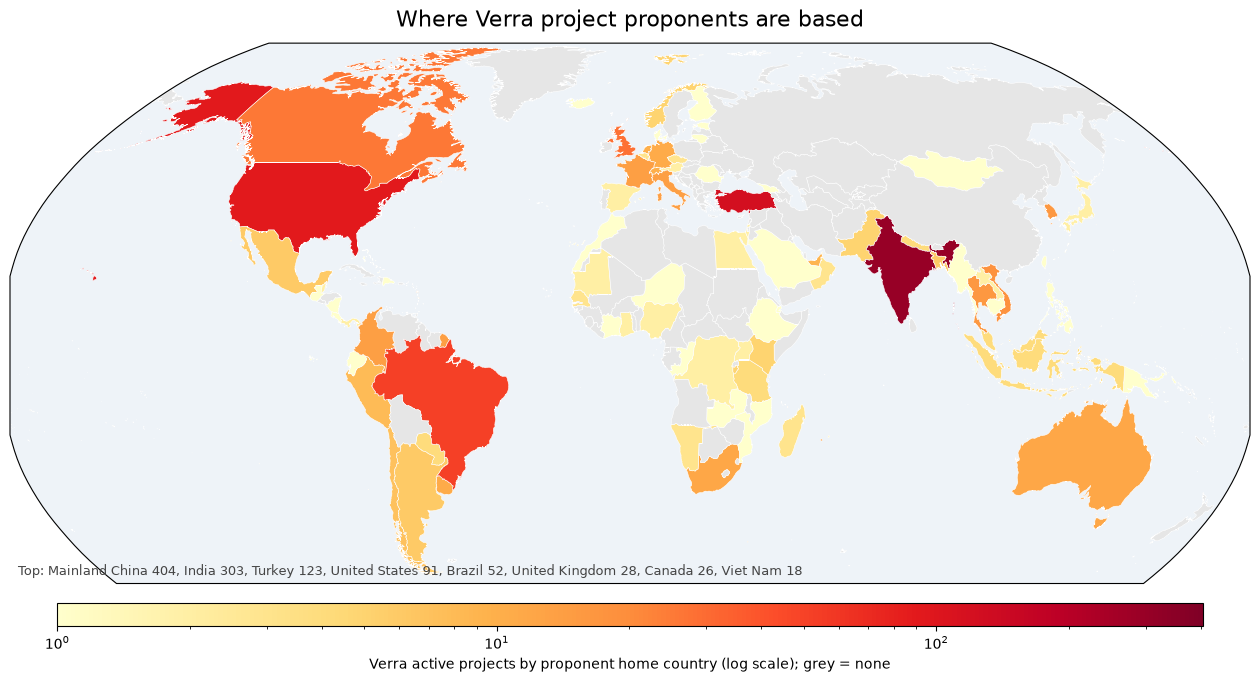

In [8]:
import cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize

# ---------------- 設定區(改這裡) ----------------
METRIC = "projects"            # "projects" 或 "companies"
CMAP = "YlOrRd"
LOG_SCALE = True
FIGSIZE = (16, 8.5)
EXTENT = [-180, 180, -58, 85]  # [經度小, 經度大, 緯度小, 緯度大];去掉南極
PROJECTION = ccrs.Robinson()
NO_DATA_COLOR = "#e6e6e6"
OCEAN_COLOR = "#eef3f8"
TITLE = "Where Verra project proponents are based"
SHOW_SMALL_MARKERS = False     # True:小國加圓點標示
SAVE_AS = PHOTO / "geography_map.png"
# --------------------------------------------------

# 我們的國名 → Natural Earth 的國名(對不上的才需要寫)
NE_NAMES = {
    "United States": "United States of America",
    "Viet Nam": "Vietnam",
    "Tanzania": "United Republic of Tanzania",
    "Congo (Democratic Republic of)": "Democratic Republic of the Congo",
    "Congo": "Republic of the Congo",
    "Bahamas": "The Bahamas",
    "Côte d'Ivoire": "Ivory Coast",
}
values = {NE_NAMES.get(c, c): v for c, v in counts[METRIC].items()}

shp = shpreader.natural_earth(resolution="50m", category="cultural", name="admin_0_countries")
records = [r for r in shpreader.Reader(shp).records() if r.attributes["ADMIN"] != "Antarctica"]
unmatched = set(values) - {r.attributes["ADMIN"] for r in records}
if unmatched:
    print("沒對到 Natural Earth 的國家:", unmatched)

vmax = counts[METRIC].max()
norm = LogNorm(vmin=1, vmax=vmax) if LOG_SCALE else Normalize(vmin=0, vmax=vmax)
cmap = plt.get_cmap(CMAP)

fig = plt.figure(figsize=FIGSIZE)
ax = plt.axes(projection=PROJECTION)
ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
ax.set_facecolor(OCEAN_COLOR)

for r in records:
    v = values.get(r.attributes["ADMIN"])
    ax.add_geometries([r.geometry], ccrs.PlateCarree(),
                      facecolor=cmap(norm(v)) if v else NO_DATA_COLOR,
                      edgecolor="white", linewidth=0.4)

if SHOW_SMALL_MARKERS:
    # 面積很小的國家用圓點標在大約的位置 (經度, 緯度)
    small = {"Singapore": (103.8, 1.35), "Luxembourg": (6.1, 49.8),
             "Bahamas": (-77.4, 25.0), "Mauritius": (57.5, -20.3)}
    for c, (lon, lat) in small.items():
        if c in counts.index:
            ax.scatter(lon, lat, s=60, transform=ccrs.PlateCarree(), zorder=5,
                       c=[cmap(norm(counts.loc[c, METRIC]))], edgecolors="black", linewidths=0.6)

sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
cb = fig.colorbar(sm, ax=ax, orientation="horizontal", fraction=0.035, pad=0.03, aspect=50)
cb.set_label(f"Verra active {METRIC} by proponent home country"
             + (" (log scale)" if LOG_SCALE else "") + "; grey = none")

top = counts[METRIC].head(8)
ax.set_title(TITLE, fontsize=16, pad=12)
fig.text(0.13, 0.17, "Top: " + ", ".join(f"{c} {int(v)}" for c, v in top.items()),
         fontsize=9, color="#444")
fig.savefig(SAVE_AS, dpi=200, bbox_inches="tight")
plt.show()